In [ ]:
print("Multimodal Fake News Verification Project")
print("Environment setup started!")

Multimodal Fake News Verification Project
Environment setup started!


In [ ]:
import sys

print("Python version:", sys.version)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Basic libraries are working!")

NumPy: 2.1.3
Pandas: 2.2.3
Basic libraries are working!


In [ ]:
import os

os.makedirs("project", exist_ok=True)
os.makedirs("project/data", exist_ok=True)
os.makedirs("project/models", exist_ok=True)
os.makedirs("project/notebooks", exist_ok=True)

print("Project folders created!")

Project folders created!


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cpu
GPU available: False
Running on CPU


In [ ]:
!pip install torch torchvision torchaudio

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_path = "/content/drive/MyDrive/AI_Fake_News_Project/dataset"

print(os.listdir(project_path))

['multimodal_validate.tsv', 'multimodal_train.tsv']


In [ ]:
import pandas as pd
import os

project_path = "/content/drive/MyDrive/AI_Fake_News_Project/dataset"

files = os.listdir(project_path)
print(files)

['multimodal_validate.tsv', 'multimodal_train.tsv']


In [ ]:
tsv_files = [f for f in files if f.endswith(".tsv")]

print("TSV files found:")
for f in tsv_files:
    print(f)

TSV files found:
multimodal_validate.tsv
multimodal_train.tsv


In [ ]:
train_file = [f for f in tsv_files if "train" in f.lower()][0]

train_path = os.path.join(project_path, train_file)

df = pd.read_csv(train_path, sep="\t")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (564000, 16)


In [ ]:
df.head()

,author,clean_title,created_utc,domain,hasImage,id,image_url,linked_submission_id,num_comments,score,subreddit,title,upvote_ratio,2_way_label,3_way_label,6_way_label
0,Alexithymia,my walgreens offbrand mucinex was engraved wit...,1.551641e+09,i.imgur.com,True,awxhir,https://external-preview.redd.it/WylDbZrnbvZdB...,NaN,2.0,12,mildlyinteresting,My Walgreens offbrand Mucinex was engraved wit...,0.84,1,0,0
1,VIDCAs17,this concerned sink with a tiny hat,1.534727e+09,i.redd.it,True,98pbid,https://preview.redd.it/wsfx0gp0f5h11.jpg?widt...,NaN,2.0,119,pareidolia,This concerned sink with a tiny hat,0.99,0,2,2
2,prometheus1123,hackers leak emails from uae ambassador to us,1.496511e+09,aljazeera.com,True,6f2cy5,https://external-preview.redd.it/6fNhdbc6K1vFA...,NaN,1.0,44,neutralnews,Hackers leak emails from UAE ambassador to US,0.92,1,0,0
3,NaN,puppy taking in the view,1.471341e+09,i.imgur.com,True,4xypkv,https://external-preview.redd.it/HLtVNhTR6wtYt...,NaN,26.0,250,photoshopbattles,PsBattle: Puppy taking in the view,0.95,1,0,0
4,3rikR3ith,i found a face in my sheet music too,1.525318e+09,i.redd.it,True,8gnet9,https://preview.redd.it/ri7ut2wn8kv01.jpg?widt...,NaN,2.0,13,pareidolia,I found a face in my sheet music too!,0.84,0,2,2


In [ ]:
print(df.columns.tolist())

['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']


In [ ]:
print(df.isnull().sum())

author                   28710
clean_title                  0
created_utc                  0
domain                  167857
hasImage                     0
id                           0
image_url                 1534
linked_submission_id    396143
num_comments            167857
score                        0
subreddit                    0
title                        0
upvote_ratio            167857
2_way_label                  0
3_way_label                  0
6_way_label                  0
dtype: int64


In [ ]:
print("2-way label distribution:")
print(df["2_way_label"].value_counts())

print("\nPercentage:")
print(
    df["2_way_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

2-way label distribution:
2_way_label
0    341919
1    222081
Name: count, dtype: int64

Percentage:
2_way_label
0    60.62
1    39.38
Name: proportion, dtype: float64


In [ ]:
print("Image availability:")
print(df["hasImage"].value_counts())

Image availability:
hasImage
True    564000
Name: count, dtype: int64


In [ ]:
data = df[[
    "clean_title",
    "image_url",
    "2_way_label"
]].copy()

print("New dataset shape:", data.shape)
data.head()

New dataset shape: (564000, 3)


,clean_title,image_url,2_way_label
0,my walgreens offbrand mucinex was engraved wit...,https://external-preview.redd.it/WylDbZrnbvZdB...,1
1,this concerned sink with a tiny hat,https://preview.redd.it/wsfx0gp0f5h11.jpg?widt...,0
2,hackers leak emails from uae ambassador to us,https://external-preview.redd.it/6fNhdbc6K1vFA...,1
3,puppy taking in the view,https://external-preview.redd.it/HLtVNhTR6wtYt...,1
4,i found a face in my sheet music too,https://preview.redd.it/ri7ut2wn8kv01.jpg?widt...,0


In [ ]:
data = data.dropna(subset=["image_url"])

print("After removing missing images:", data.shape)

After removing missing images: (562466, 3)


In [ ]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 2190


In [ ]:
print("Duplicate titles:", data["clean_title"].duplicated().sum())

Duplicate titles: 61343


In [ ]:
print(data["2_way_label"].value_counts())

2_way_label
0    341460
1    221006
Name: count, dtype: int64


In [ ]:
data = data.drop_duplicates().reset_index(drop=True)

print("Dataset after removing exact duplicates:")
print(data.shape)

Dataset after removing exact duplicates:
(560276, 3)


In [ ]:
data["text_length"] = data["clean_title"].str.len()

print(data["text_length"].describe())

count    560276.000000
mean         41.883145
std          31.801679
min           1.000000
25%          19.000000
50%          34.000000
75%          57.000000
max        2785.000000
Name: text_length, dtype: float64


In [ ]:
data[["clean_title", "text_length"]].sort_values(
    "text_length"
).head(10)

,clean_title,text_length
147742,u,1
96724,t,1
24246,p,1
191111,v,1
447672,b,1
411000,o,1
259378,d,1
147713,p,1
104557,d,1
88149,x,1


In [ ]:
data[["clean_title", "text_length"]].sort_values(
    "text_length",
    ascending=False
).head(10)

,clean_title,text_length
103541,what the fuck did you just fucking say about m...,2785
351005,what the fuck did you just fucking say about m...,1467
360932,howdy yall my name is kim john im a year old k...,1143
284212,our battle has been long and drawn out weve su...,726
296818,dovakhiin dovakhiin naal ok zin los vahriin wa...,490
256796,news update trump disqualified from republican...,479
5567,i know who you are i know what you want you ar...,470
265098,warning house of cards season spoiler do not c...,465
105758,martha got home early from work her son was in...,435
409579,the assignment was to take the hill there were...,419


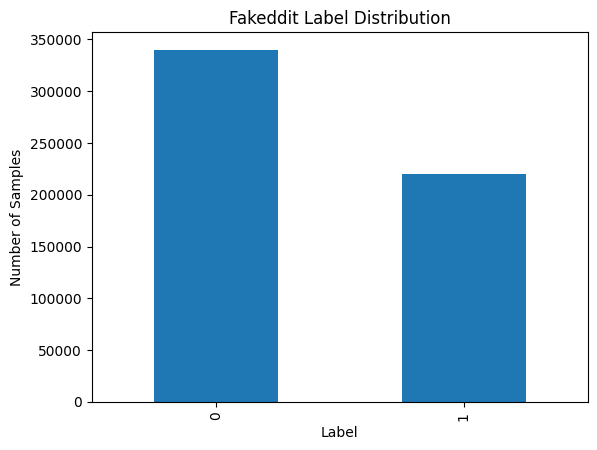

In [ ]:
import matplotlib.pyplot as plt

data["2_way_label"].value_counts().plot(kind="bar")

plt.title("Fakeddit Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Samples")
plt.show()

In [ ]:
before = len(data)

data = data[data["text_length"] >= 10].copy()

after = len(data)

print("Before:", before)
print("After:", after)
print("Removed:", before - after)

Before: 560276
After: 518501
Removed: 41775


In [ ]:
print("Texts > 500 chars:", (data["text_length"] > 500).sum())
print("Texts > 1000 chars:", (data["text_length"] > 1000).sum())

Texts > 500 chars: 4
Texts > 1000 chars: 3


In [ ]:
print(
    round(
        (data["text_length"] > 500).mean() * 100,
        2
    ),
    "% of dataset has text > 500 characters"
)

0.0 % of dataset has text > 500 characters


In [ ]:
clean_path = "/content/drive/MyDrive/AI_Fake_News_Project/dataset/fakeddit_clean.csv"

data.to_csv(clean_path, index=False)

print("Clean dataset saved!")
print(clean_path)

Clean dataset saved!
/content/drive/MyDrive/AI_Fake_News_Project/dataset/fakeddit_clean.csv


In [ ]:
print("Final samples:", len(data))
print("Columns:", data.columns.tolist())

Final samples: 518501
Columns: ['clean_title', 'image_url', '2_way_label', 'text_length']


In [ ]:
from sklearn.model_selection import train_test_split

# Features and target
X = data[["clean_title", "image_url", "text_length"]]
y = data["2_way_label"]

# First split: 80% Train, 20% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 10% Validation, 10% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nTotal:", len(X_train) + len(X_val) + len(X_test))

Train: 414800
Validation: 51850
Test: 51851

Total: 518501


In [ ]:
print("Train label distribution:")
print(y_train.value_counts())

print("\nValidation label distribution:")
print(y_val.value_counts())

print("\nTest label distribution:")
print(y_test.value_counts())

Train label distribution:
2_way_label
0    239358
1    175442
Name: count, dtype: int64

Validation label distribution:
2_way_label
0    29920
1    21930
Name: count, dtype: int64

Test label distribution:
2_way_label
0    29920
1    21931
Name: count, dtype: int64


In [ ]:
print("\nTrain percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation percentages:")
print((y_val.value_counts(normalize=True) * 100).round(2))

print("\nTest percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Train percentages:
2_way_label
0    57.7
1    42.3
Name: proportion, dtype: float64

Validation percentages:
2_way_label
0    57.7
1    42.3
Name: proportion, dtype: float64

Test percentages:
2_way_label
0    57.7
1    42.3
Name: proportion, dtype: float64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = vectorizer.fit_transform(X_train["clean_title"])

X_val_tfidf = vectorizer.transform(X_val["clean_title"])
X_test_tfidf = vectorizer.transform(X_test["clean_title"])

print("Train shape:", X_train_tfidf.shape)
print("Validation shape:", X_val_tfidf.shape)
print("Test shape:", X_test_tfidf.shape)

Train shape: (414800, 50000)
Validation shape: (51850, 50000)
Test shape: (51851, 50000)


In [ ]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_val_pred = model.predict(X_val_tfidf)

val_accuracy = accuracy_score(y_val, y_val_pred)

print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")

Validation Accuracy: 82.46 %


In [ ]:
print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Non-Fake", "Fake"]
))


Classification Report:
              precision    recall  f1-score   support

    Non-Fake       0.87      0.82      0.84     29920
        Fake       0.77      0.83      0.80     21930

    accuracy                           0.82     51850
   macro avg       0.82      0.83      0.82     51850
weighted avg       0.83      0.82      0.83     51850



In [ ]:
y_test_pred = model.predict(X_test_tfidf)

test_accuracy = accuracy_score(y_test, y_test_pred)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Non-Fake", "Fake"]
))

Test Accuracy: 82.43 %

Classification Report:
              precision    recall  f1-score   support

    Non-Fake       0.87      0.82      0.84     29920
        Fake       0.77      0.83      0.80     21931

    accuracy                           0.82     51851
   macro avg       0.82      0.82      0.82     51851
weighted avg       0.83      0.82      0.83     51851



In [ ]:
cm = confusion_matrix(y_test, y_test_pred)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[24594  5326]
 [ 3782 18149]]


In [ ]:
test_results = X_test.copy()

test_results["actual"] = y_test
test_results["predicted"] = y_test_pred

test_results["fake_probability"] = model.predict_proba(X_test_tfidf)[:, 1]

print(test_results.head())

                                              clean_title  \
401105                               this field of tulips   
96930   i have a single white hair on my hand that gro...   
422792                   censored jewel from rmineralporn   
535652  messageinabottle sent in author found finally ...   
207383            the shadow that this spiral chord casts   

                                                image_url  text_length  \
401105  https://preview.redd.it/n9dvn7oiayqy.jpg?width...           20   
96930   https://external-preview.redd.it/bF8sKvKfDnCiQ...           63   
422792  https://external-preview.redd.it/5fFZm_yP3yIGj...           32   
535652  https://external-preview.redd.it/Tb_ATl0NE1iFt...           71   
207383  https://preview.redd.it/rgcgy7aibvd31.jpg?widt...           39   

        actual  predicted  fake_probability  
401105       1          1          0.581501  
96930        1          1          0.891043  
422792       0          0          0.280608  
5356

In [ ]:
test_results = X_test.copy()

test_results["actual"] = y_test
test_results["predicted"] = y_test_pred

test_results["fake_probability"] = model.predict_proba(X_test_tfidf)[:, 1]

print(test_results.head())

                                              clean_title  \
401105                               this field of tulips   
96930   i have a single white hair on my hand that gro...   
422792                   censored jewel from rmineralporn   
535652  messageinabottle sent in author found finally ...   
207383            the shadow that this spiral chord casts   

                                                image_url  text_length  \
401105  https://preview.redd.it/n9dvn7oiayqy.jpg?width...           20   
96930   https://external-preview.redd.it/bF8sKvKfDnCiQ...           63   
422792  https://external-preview.redd.it/5fFZm_yP3yIGj...           32   
535652  https://external-preview.redd.it/Tb_ATl0NE1iFt...           71   
207383  https://preview.redd.it/rgcgy7aibvd31.jpg?widt...           39   

        actual  predicted  fake_probability  
401105       1          1          0.581501  
96930        1          1          0.891043  
422792       0          0          0.280608  
5356

In [ ]:
errors = test_results[
    test_results["actual"] != test_results["predicted"]
].copy()

print("Total errors:", len(errors))
print("Error percentage:", round(len(errors) / len(test_results) * 100, 2), "%")

Total errors: 9108
Error percentage: 17.57 %


In [ ]:
errors[
    ["clean_title", "actual", "predicted", "fake_probability"]
].head(20)

,clean_title,actual,predicted,fake_probability
534537,trex lighsaber fight,1,0,0.207738
78463,biden nixes the idea of dnc chair run,1,0,0.128240
243646,these newborn pups are tired,0,1,0.768561
371253,mailbox ghillie suit,1,0,0.322914
270582,greatest living president hones painting prowess,1,0,0.145364
510679,knockoffs and real,1,0,0.286751
549194,the afternoon tea i enjoyed with my wife yeste...,1,0,0.222890
39817,california once compared to greece is now the ...,0,1,0.901937
325849,gay pride israel,0,1,0.575483
552270,charges dropped against florida man because th...,1,0,0.305135


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cpu
GPU available: False


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cpu
GPU available: False


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

clean_path = "/content/drive/MyDrive/AI_Fake_News_Project/dataset/fakeddit_clean.csv"

data = pd.read_csv(clean_path)

print("Dataset shape:", data.shape)
print(data.head())

Dataset shape: (518501, 4)
                                         clean_title  \
0  my walgreens offbrand mucinex was engraved wit...   
1                this concerned sink with a tiny hat   
2      hackers leak emails from uae ambassador to us   
3                           puppy taking in the view   
4               i found a face in my sheet music too   

                                           image_url  2_way_label  text_length  
0  https://external-preview.redd.it/WylDbZrnbvZdB...            1           92  
1  https://preview.redd.it/wsfx0gp0f5h11.jpg?widt...            0           35  
2  https://external-preview.redd.it/6fNhdbc6K1vFA...            1           45  
3  https://external-preview.redd.it/HLtVNhTR6wtYt...            1           24  
4  https://preview.redd.it/ri7ut2wn8kv01.jpg?widt...            0           36  


In [ ]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("GPU Memory:",
      round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
      "GB")

GPU: Tesla T4
GPU Memory: 14.56 GB


In [ ]:
from sklearn.model_selection import train_test_split

X = data[["clean_title", "image_url", "text_length"]]
y = data["2_way_label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 414800
Validation: 51850
Test: 51851


In [ ]:
!pip install -q transformers datasets accelerate

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

transformer_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

print("Transformer model loaded!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Transformer model loaded!


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transformer_model.to(device)

print("Using device:", device)

Using device: cuda


In [ ]:
sample_text = X_train["clean_title"].iloc[0]

tokens = tokenizer(
    sample_text,
    padding="max_length",
    truncation=True,
    max_length=128
)

print("Original text:")
print(sample_text)

print("\nInput IDs:")
print(tokens["input_ids"][:20])

print("\nAttention mask:")
print(tokens["attention_mask"][:20])

Original text:
giannis dunking

Input IDs:
[101, 27699, 27803, 24654, 6834, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Attention mask:
[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [ ]:

# Restore project setup after Colab runtime reset

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Load saved dataset
clean_path = "/content/drive/MyDrive/AI_Fake_News_Project/dataset/fakeddit_clean.csv"
data = pd.read_csv(clean_path)

# Recreate the same split as before
X = data[["clean_title", "image_url", "text_length"]]
y = data["2_way_label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Restore tokenizer and pretrained DistilBERT
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

transformer_model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=2
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
transformer_model.to(device)

print("\n--- Project restored ---")
print("Dataset:", data.shape)
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))
print("GPU:", torch.cuda.is_available())
print("Device:", device)

Mounted at /content/drive


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



--- Project restored ---
Dataset: (518501, 4)
Train: 414800
Validation: 51850
Test: 51851
GPU: True
Device: cuda


In [ ]:

from torch.utils.data import Dataset, DataLoader

class FakeNewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts.reset_index(drop=True)
        self.labels = labels.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts.iloc[idx])
        label = int(self.labels.iloc[idx])

        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)
        }

# Controlled experiment subsets
train_dataset = FakeNewsDataset(
    X_train["clean_title"].iloc[:5000],
    y_train.iloc[:5000],
    tokenizer
)

val_dataset = FakeNewsDataset(
    X_val["clean_title"].iloc[:1000],
    y_val.iloc[:1000],
    tokenizer
)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train samples: 5000
Validation samples: 1000
Train batches: 313
Validation batches: 63


In [ ]:

batch = next(iter(train_loader))

print("Input IDs shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)
print("Labels shape:", batch["labels"].shape)
print("First 5 labels:", batch["labels"][:5])

Input IDs shape: torch.Size([16, 128])
Attention mask shape: torch.Size([16, 128])
Labels shape: torch.Size([16])
First 5 labels: tensor([1, 0, 0, 0, 1])


In [ ]:

from torch.optim import AdamW

# Training settings
learning_rate = 2e-5

optimizer = AdamW(
    transformer_model.parameters(),
    lr=learning_rate
)

print("Optimizer ready!")
print("Learning rate:", learning_rate)
print("Device:", device)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Optimizer ready!
Learning rate: 2e-05
Device: cuda
Training samples: 5000
Validation samples: 1000


In [ ]:

from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss = 0

    progress = tqdm(loader, desc="Training")

    for batch in progress:
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            labels=batch["labels"]
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / len(loader)

print("Training function ready!")

Training function ready!


In [ ]:
train_loss = train_one_epoch(
    transformer_model,
    train_loader,
    optimizer,
    device
)

print(f"Training Loss: {train_loss:.4f}")

Training:   0%|          | 0/313 [00:00<?, ?it/s]

Training Loss: 0.5054


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, f1_score
from tqdm.auto import tqdm

def evaluate_model(model, loader, device):
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating"):
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            predictions = torch.argmax(outputs.logits, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(batch["labels"].cpu().numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(all_labels, all_predictions, average="macro")

    print(f"Validation Accuracy: {accuracy:.4f}")
    print(f"Validation Macro F1: {macro_f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(
        all_labels,
        all_predictions,
        target_names=["Non-Fake", "Fake"],
        digits=4
    ))

    return accuracy, macro_f1

val_accuracy, val_f1 = evaluate_model(
    transformer_model,
    val_loader,
    device
)

Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Accuracy: 0.8030
Validation Macro F1: 0.7957

Classification Report:
              precision    recall  f1-score   support

    Non-Fake     0.8185    0.8508    0.8343       583
        Fake     0.7792    0.7362    0.7571       417

    accuracy                         0.8030      1000
   macro avg     0.7988    0.7935    0.7957      1000
weighted avg     0.8021    0.8030    0.8021      1000



In [ ]:
train_loss = train_one_epoch(
    transformer_model,
    train_loader,
    optimizer,
    device
)

print(f"Epoch 2 Training Loss: {train_loss:.4f}")

val_accuracy, val_f1 = evaluate_model(
    transformer_model,
    val_loader,
    device
)

Training:   0%|          | 0/313 [00:00<?, ?it/s]

Epoch 2 Training Loss: 0.3425


Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Accuracy: 0.8170
Validation Macro F1: 0.8107

Classification Report:
              precision    recall  f1-score   support

    Non-Fake     0.8333    0.8576    0.8453       583
        Fake     0.7925    0.7602    0.7760       417

    accuracy                         0.8170      1000
   macro avg     0.8129    0.8089    0.8107      1000
weighted avg     0.8163    0.8170    0.8164      1000



In [ ]:
train_loss = train_one_epoch(
    transformer_model,
    train_loader,
    optimizer,
    device
)

print(f"Epoch 3 Training Loss: {train_loss:.4f}")

val_accuracy, val_f1 = evaluate_model(
    transformer_model,
    val_loader,
    device
)

Training:   0%|          | 0/313 [00:00<?, ?it/s]

Epoch 3 Training Loss: 0.2041


Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Accuracy: 0.7930
Validation Macro F1: 0.7924

Classification Report:
              precision    recall  f1-score   support

    Non-Fake     0.8983    0.7273    0.8038       583
        Fake     0.6989    0.8849    0.7810       417

    accuracy                         0.7930      1000
   macro avg     0.7986    0.8061    0.7924      1000
weighted avg     0.8151    0.7930    0.7943      1000



In [ ]:
import os

save_path = (
    "/content/drive/MyDrive/AI_Fake_News_Project/"
    "models/distilbert_epoch3"
)

os.makedirs(save_path, exist_ok=True)

transformer_model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print("Current DistilBERT model saved to Google Drive!")
print(save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Current DistilBERT model saved to Google Drive!
/content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_epoch3


In [ ]:
epoch_results = [
    {"epoch": 1, "train_loss": 0.5054, "val_accuracy": 0.8030, "val_macro_f1": 0.7957},
    {"epoch": 2, "train_loss": 0.3425, "val_accuracy": 0.8170, "val_macro_f1": 0.8107},
    {"epoch": 3, "train_loss": 0.2041, "val_accuracy": 0.7930, "val_macro_f1": 0.7924},
]

import pandas as pd

results_df = pd.DataFrame(epoch_results)
display(results_df)

best_epoch = results_df.loc[results_df["val_macro_f1"].idxmax()]
print("Best recorded epoch:", int(best_epoch["epoch"]))
print("Best validation Macro F1:", best_epoch["val_macro_f1"])

,epoch,train_loss,val_accuracy,val_macro_f1
0,1,0.5054,0.803,0.7957
1,2,0.3425,0.817,0.8107
2,3,0.2041,0.793,0.7924


Best recorded epoch: 2
Best validation Macro F1: 0.8107


In [ ]:
from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW
import os
import torch

model_name = "distilbert-base-uncased"

transformer_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
).to(device)

optimizer = AdamW(
    transformer_model.parameters(),
    lr=2e-5
)

best_model_path = (
    "/content/drive/MyDrive/AI_Fake_News_Project/"
    "models/distilbert_best"
)

os.makedirs(best_model_path, exist_ok=True)

print("Fresh DistilBERT model ready!")
print("Best-model folder:", best_model_path)
print("Device:", device)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh DistilBERT model ready!
Best-model folder: /content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_best
Device: cuda


In [ ]:
best_f1 = 0.0
history = []

for epoch in range(1, 4):
    print(f"\n{'='*15} Epoch {epoch} {'='*15}")

    train_loss = train_one_epoch(
        transformer_model,
        train_loader,
        optimizer,
        device
    )

    val_accuracy, val_f1 = evaluate_model(
        transformer_model,
        val_loader,
        device
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_f1
    })

    if val_f1 > best_f1:
        best_f1 = val_f1

        transformer_model.save_pretrained(best_model_path)
        tokenizer.save_pretrained(best_model_path)

        print(f"Best checkpoint saved! Macro F1: {best_f1:.4f}")

history_df = pd.DataFrame(history)
display(history_df)

print("Best validation Macro F1:", round(best_f1, 4))
print("Saved folder:", best_model_path)


=============== Epoch 1 ===============


Training:   0%|          | 0/313 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Accuracy: 0.8040
Validation Macro F1: 0.7973

Classification Report:
              precision    recall  f1-score   support

    Non-Fake     0.8230    0.8456    0.8342       583
        Fake     0.7756    0.7458    0.7604       417

    accuracy                         0.8040      1000
   macro avg     0.7993    0.7957    0.7973      1000
weighted avg     0.8032    0.8040    0.8034      1000



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Training:   0%|          | 0/313 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Accuracy: 0.7920
Validation Macro F1: 0.7882

Classification Report:
              precision    recall  f1-score   support

    Non-Fake     0.8403    0.7942    0.8166       583
        Fake     0.7327    0.7890    0.7598       417

    accuracy                         0.7920      1000
   macro avg     0.7865    0.7916    0.7882      1000
weighted avg     0.7954    0.7920    0.7929      1000



,epoch,train_loss,val_accuracy,val_macro_f1
0,1,0.503691,0.804,0.797285
1,2,0.335730,0.801,0.799813
2,3,0.203071,0.792,0.788197


Best validation Macro F1: 0.7998
Saved folder: /content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_best


In [ ]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

best_model_path = (
    "/content/drive/MyDrive/AI_Fake_News_Project/"
    "models/distilbert_best"
)

best_tokenizer = AutoTokenizer.from_pretrained(best_model_path)

best_model = AutoModelForSequenceClassification.from_pretrained(
    best_model_path
).to(device)

best_model.eval()

print("Best checkpoint loaded successfully!")
print("Device:", device)
print("Model:", best_model.config._name_or_path)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Best checkpoint loaded successfully!
Device: cuda
Model: /content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_best


In [ ]:
saved_val_accuracy, saved_val_f1 = evaluate_model(
    best_model,
    val_loader,
    device
)

Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Accuracy: 0.8010
Validation Macro F1: 0.7998

Classification Report:
              precision    recall  f1-score   support

    Non-Fake     0.8887    0.7530    0.8152       583
        Fake     0.7154    0.8681    0.7844       417

    accuracy                         0.8010      1000
   macro avg     0.8020    0.8106    0.7998      1000
weighted avg     0.8164    0.8010    0.8024      1000



In [ ]:
from torch.utils.data import DataLoader

# Larger training and validation datasets
train_dataset_large = FakeNewsDataset(
    X_train["clean_title"].iloc[:20000],
    y_train.iloc[:20000],
    tokenizer
)

val_dataset_large = FakeNewsDataset(
    X_val["clean_title"].iloc[:2000],
    y_val.iloc[:2000],
    tokenizer
)

train_loader_large = DataLoader(
    train_dataset_large,
    batch_size=16,
    shuffle=True
)

val_loader_large = DataLoader(
    val_dataset_large,
    batch_size=16,
    shuffle=False
)

print("Training samples:", len(train_dataset_large))
print("Validation samples:", len(val_dataset_large))
print("Training batches:", len(train_loader_large))
print("Validation batches:", len(val_loader_large))

Training samples: 20000
Validation samples: 2000
Training batches: 1250
Validation batches: 125


In [ ]:
from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW
import os
import torch

best_model_path = (
    "/content/drive/MyDrive/AI_Fake_News_Project/"
    "models/distilbert_best"
)

best_model = AutoModelForSequenceClassification.from_pretrained(
    best_model_path
).to(device)

optimizer = AdamW(
    best_model.parameters(),
    lr=2e-5
)

best_f1 = 0.0

print("Best checkpoint loaded!")
print("Training samples:", len(train_dataset_large))
print("Validation samples:", len(val_dataset_large))
print("GPU:", torch.cuda.get_device_name(0))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Best checkpoint loaded!
Training samples: 20000
Validation samples: 2000
GPU: Tesla T4


In [ ]:
best_f1 = 0.0
history_large = []

for epoch in range(1, 4):
    print(f"\n===== Large Dataset Epoch {epoch} =====")

    train_loss = train_one_epoch(
        best_model,
        train_loader_large,
        optimizer,
        device
    )

    val_accuracy, val_f1 = evaluate_model(
        best_model,
        val_loader_large,
        device
    )

    history_large.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_f1
    })

    if val_f1 > best_f1:
        best_f1 = val_f1

        best_model.save_pretrained(best_model_path)
        tokenizer.save_pretrained(best_model_path)

        print(f"Best checkpoint saved! Macro F1: {best_f1:.4f}")

display(pd.DataFrame(history_large))
print("Best validation Macro F1:", round(best_f1, 4))


===== Large Dataset Epoch 1 =====


Training:   0%|          | 0/1250 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/125 [00:00<?, ?it/s]

Validation Accuracy: 0.8300
Validation Macro F1: 0.8236

Classification Report:
              precision    recall  f1-score   support

    Non-Fake     0.8239    0.8932    0.8571      1142
        Fake     0.8399    0.7459    0.7901       858

    accuracy                         0.8300      2000
   macro avg     0.8319    0.8195    0.8236      2000
weighted avg     0.8308    0.8300    0.8284      2000



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Validation Accuracy: 0.8345
Validation Macro F1: 0.8311

Classification Report:
              precision    recall  f1-score   support

    Non-Fake     0.8554    0.8546    0.8550      1142
        Fake     0.8068    0.8077    0.8072       858

    accuracy                         0.8345      2000
   macro avg     0.8311    0.8312    0.8311      2000
weighted avg     0.8345    0.8345    0.8345      2000



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best checkpoint saved! Macro F1: 0.8311


,epoch,train_loss,val_accuracy,val_macro_f1
0,1,0.362520,0.8300,0.823633
1,2,0.239628,0.8210,0.819788
2,3,0.146220,0.8345,0.831119


Best validation Macro F1: 0.8311


In [ ]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

best_model_path = (
    "/content/drive/MyDrive/AI_Fake_News_Project/"
    "models/distilbert_best"
)

best_tokenizer = AutoTokenizer.from_pretrained(best_model_path)

best_model = AutoModelForSequenceClassification.from_pretrained(
    best_model_path
).to(device)

best_model.eval()

print("Best model reloaded successfully!")
print("Device:", device)

saved_accuracy, saved_f1 = evaluate_model(
    best_model,
    val_loader_large,
    device
)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Best model reloaded successfully!
Device: cuda


Evaluating:   0%|          | 0/125 [00:00<?, ?it/s]

Validation Accuracy: 0.8345
Validation Macro F1: 0.8311

Classification Report:
              precision    recall  f1-score   support

    Non-Fake     0.8554    0.8546    0.8550      1142
        Fake     0.8068    0.8077    0.8072       858

    accuracy                         0.8345      2000
   macro avg     0.8311    0.8312    0.8311      2000
weighted avg     0.8345    0.8345    0.8345      2000



In [ ]:
# Check image URL availability
print("Total dataset rows:", len(data))
print("Missing image URLs:", data["image_url"].isna().sum())
print("Unique image URLs:", data["image_url"].nunique())

print("\nSample image URLs:")
for url in data["image_url"].dropna().head(5):
    print(url)

Total dataset rows: 518501
Missing image URLs: 0
Unique image URLs: 506326

Sample image URLs:
https://external-preview.redd.it/WylDbZrnbvZdBpgfa3ntxYf17CBHndiJWHylVm2j_nY.jpg?width=320&crop=smart&auto=webp&s=449659a10792de4d55c2f27d2176fdc8bc66e72a
https://preview.redd.it/wsfx0gp0f5h11.jpg?width=320&crop=smart&auto=webp&s=6267a3ae11e616453e129c58ae34635b98c4ab37
https://external-preview.redd.it/6fNhdbc6K1vFAZX95ed-ZMLDlASqmpixvAxmXqHhfHs.jpg?width=320&crop=smart&auto=webp&s=f263f843e91b7dbea1d1157031f7ea0d555186ed
https://external-preview.redd.it/HLtVNhTR6wtYtnvL8RKfmZFdKQ7tVz42WCiH3jSGiIk.jpg?width=320&crop=smart&auto=webp&s=2d60c452b15d7d86b46b65e06da9a6e42f10d5df
https://preview.redd.it/ri7ut2wn8kv01.jpg?width=320&crop=smart&auto=webp&s=d44a419480c2073a2f0f3fa5f3701b308271331d


In [ ]:
import requests
from PIL import Image
from io import BytesIO

sample_urls = data["image_url"].dropna().head(5).tolist()

for i, url in enumerate(sample_urls, start=1):
    try:
        response = requests.get(
            url,
            timeout=15,
            headers={"User-Agent": "Mozilla/5.0"}
        )

        response.raise_for_status()

        image = Image.open(BytesIO(response.content))
        image.verify()

        print(f"Image {i}: Accessible | Format: {image.format}")

    except Exception as e:
        print(f"Image {i}: Failed | {type(e).__name__}: {e}")

Image 1: Accessible | Format: JPEG
Image 2: Failed | HTTPError: 404 Client Error: Not Found for url: https://preview.redd.it/wsfx0gp0f5h11.jpg?width=320&crop=smart&auto=webp&s=6267a3ae11e616453e129c58ae34635b98c4ab37
Image 3: Accessible | Format: JPEG
Image 4: Accessible | Format: JPEG
Image 5: Failed | HTTPError: 404 Client Error: Not Found for url: https://preview.redd.it/ri7ut2wn8kv01.jpg?width=320&crop=smart&auto=webp&s=d44a419480c2073a2f0f3fa5f3701b308271331d


In [ ]:
import requests
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from PIL import Image
from io import BytesIO

# 100 distinct image URLs
sample_urls = data["image_url"].drop_duplicates().head(100).tolist()

def check_image(url):
    try:
        response = requests.get(
            url,
            timeout=12,
            headers={"User-Agent": "Mozilla/5.0"}
        )
        response.raise_for_status()

        image = Image.open(BytesIO(response.content))
        image.verify()

        return True
    except Exception:
        return False

with ThreadPoolExecutor(max_workers=8) as executor:
    results = list(tqdm(
        executor.map(check_image, sample_urls),
        total=len(sample_urls),
        desc="Checking images"
    ))

accessible = sum(results)
failed = len(results) - accessible

print("Total checked:", len(results))
print("Accessible:", accessible)
print("Failed:", failed)
print(f"Availability rate: {accessible / len(results) * 100:.1f}%")

Checking images:   0%|          | 0/100 [00:00<?, ?it/s]

Total checked: 100
Accessible: 95
Failed: 5
Availability rate: 95.0%


In [ ]:
# Select a reproducible, stratified subset for the image experiment
from sklearn.model_selection import train_test_split

image_data = data[
    ["clean_title", "image_url", "2_way_label"]
].drop_duplicates(subset=["image_url"]).copy()

image_subset, _ = train_test_split(
    image_data,
    train_size=2000,
    random_state=42,
    stratify=image_data["2_way_label"]
)

image_subset = image_subset.reset_index(drop=True)

print("Image subset size:", len(image_subset))
print("\nLabel distribution:")
print(image_subset["2_way_label"].value_counts())

Image subset size: 2000

Label distribution:
2_way_label
0    1165
1     835
Name: count, dtype: int64


In [ ]:
import os
import requests
import pandas as pd
from PIL import Image
from io import BytesIO
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

image_folder = (
    "/content/drive/MyDrive/AI_Fake_News_Project/"
    "images_subset"
)
os.makedirs(image_folder, exist_ok=True)

pilot = image_subset.head(200).copy()

def download_image(item):
    idx, row = item
    try:
        response = requests.get(
            row["image_url"],
            timeout=15,
            headers={"User-Agent": "Mozilla/5.0"}
        )
        response.raise_for_status()

        image = Image.open(BytesIO(response.content)).convert("RGB")
        image = image.resize((224, 224))

        filename = f"image_{idx:04d}.jpg"
        filepath = os.path.join(image_folder, filename)
        image.save(filepath, "JPEG", quality=90)

        return {
            "subset_index": idx,
            "filename": filename,
            "clean_title": row["clean_title"],
            "image_url": row["image_url"],
            "2_way_label": int(row["2_way_label"]),
            "status": "success"
        }

    except Exception as e:
        return {
            "subset_index": idx,
            "image_url": row["image_url"],
            "2_way_label": int(row["2_way_label"]),
            "status": f"failed: {type(e).__name__}"
        }

with ThreadPoolExecutor(max_workers=6) as executor:
    results = list(tqdm(
        executor.map(download_image, pilot.iterrows()),
        total=len(pilot),
        desc="Downloading pilot images"
    ))

manifest = pd.DataFrame(results)
manifest_path = os.path.join(image_folder, "pilot_manifest.csv")
manifest.to_csv(manifest_path, index=False)

print("Records tested:", len(manifest))
print("Images saved:", (manifest["status"] == "success").sum())
print("Failed:", (~(manifest["status"] == "success")).sum())
print("Manifest saved:", manifest_path)

Records tested: 200
Images saved: 195
Failed: 5
Manifest saved: /content/drive/MyDrive/AI_Fake_News_Project/images_subset/pilot_manifest.csv


In [ ]:
remaining = image_subset.iloc[200:].copy()

with ThreadPoolExecutor(max_workers=6) as executor:
    remaining_results = list(tqdm(
        executor.map(download_image, remaining.iterrows()),
        total=len(remaining),
        desc="Downloading remaining images"
    ))

remaining_manifest = pd.DataFrame(remaining_results)

# Combine with the existing pilot manifest
full_manifest = pd.concat(
    [manifest, remaining_manifest],
    ignore_index=True
)

full_manifest_path = os.path.join(
    image_folder,
    "image_manifest.csv"
)
full_manifest.to_csv(full_manifest_path, index=False)

successful = (full_manifest["status"] == "success").sum()
failed = len(full_manifest) - successful

print("Total records processed:", len(full_manifest))
print("Images saved:", successful)
print("Failed:", failed)
print(f"Success rate: {successful / len(full_manifest) * 100:.2f}%")
print("Manifest:", full_manifest_path)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Total records processed: 2000
Images saved: 1901
Failed: 99
Success rate: 95.05%
Manifest: /content/drive/MyDrive/AI_Fake_News_Project/images_subset/image_manifest.csv


In [ ]:
print("Dataset columns:", data.columns.tolist())

print("\nTrain split type:", type(X_train).__name__)
print("Train rows:", len(X_train))
print("Train index sample:", X_train.index[:5].tolist())

print("\nValidation rows:", len(X_val))
print("Validation index sample:", X_val.index[:5].tolist())

print("\nTest rows:", len(X_test))
print("Test index sample:", X_test.index[:5].tolist())

print("\nDownloaded manifest rows:", len(full_manifest))
print("Successful images:", (full_manifest["status"] == "success").sum())

Dataset columns: ['clean_title', 'image_url', '2_way_label', 'text_length']

Train split type: DataFrame
Train rows: 414800
Train index sample: [434166, 224983, 240786, 31124, 4096]

Validation rows: 51850
Validation index sample: [435138, 79344, 511650, 489801, 182044]

Test rows: 51851
Test index sample: [371220, 89832, 391253, 495637, 192080]

Downloaded manifest rows: 2000
Successful images: 1901


In [ ]:
import os
import pandas as pd

image_folder = (
    "/content/drive/MyDrive/AI_Fake_News_Project/"
    "images_subset"
)

manifest_path = os.path.join(
    image_folder, "image_manifest.csv"
)

full_manifest = pd.read_csv(manifest_path)

# Keep only successfully downloaded images
valid_images = full_manifest[
    full_manifest["status"] == "success"
].copy()

# Create URL sets from the original data splits
train_urls = set(X_train["image_url"])
val_urls = set(X_val["image_url"])
test_urls = set(X_test["image_url"])

# Assign each image to its original split
valid_images["split"] = valid_images["image_url"].map(
    lambda url: (
        "train" if url in train_urls
        else "validation" if url in val_urls
        else "test" if url in test_urls
        else "unknown"
    )
)

print("Successfully downloaded images:", len(valid_images))
print("\nImages per original split:")
print(valid_images["split"].value_counts())

print("\nLabel distribution by split:")
print(pd.crosstab(
    valid_images["split"],
    valid_images["2_way_label"]
))

# Save split-aware manifest
split_manifest_path = os.path.join(
    image_folder, "image_split_manifest.csv"
)
valid_images.to_csv(split_manifest_path, index=False)

print("\nSplit manifest saved to:")
print(split_manifest_path)

Successfully downloaded images: 1901

Images per original split:
split
train         1491
validation     215
test           195
Name: count, dtype: int64

Label distribution by split:
2_way_label    0    1
split                
test         103   92
train        898  593
validation   118   97

Split manifest saved to:
/content/drive/MyDrive/AI_Fake_News_Project/images_subset/image_split_manifest.csv


In [ ]:
import torch
import torchvision
from torchvision import transforms
from PIL import Image
from torch.utils.data import Dataset, DataLoader

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

# Standard ImageNet normalization for pretrained ResNet18
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("\nImage preprocessing ready!")
print("Image size: 224 x 224")
print("Training augmentation: Random horizontal flip")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True

Image preprocessing ready!
Image size: 224 x 224
Training augmentation: Random horizontal flip


In [ ]:
import os
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn

image_folder = (
    "/content/drive/MyDrive/AI_Fake_News_Project/"
    "images_subset"
)

split_df = pd.read_csv(
    os.path.join(image_folder, "image_split_manifest.csv")
)

class NewsImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        path = os.path.join(image_folder, row["filename"])

        with Image.open(path) as img:
            image = self.transform(img.convert("RGB"))

        label = int(row["2_way_label"])
        return image, torch.tensor(label, dtype=torch.long)

train_df = split_df[split_df["split"] == "train"].copy()
val_df = split_df[split_df["split"] == "validation"].copy()
test_df = split_df[split_df["split"] == "test"].copy()

train_image_ds = NewsImageDataset(train_df, train_transform)
val_image_ds = NewsImageDataset(val_df, eval_transform)
test_image_ds = NewsImageDataset(test_df, eval_transform)

train_image_loader = DataLoader(
    train_image_ds, batch_size=32, shuffle=True, num_workers=2
)
val_image_loader = DataLoader(
    val_image_ds, batch_size=32, shuffle=False, num_workers=2
)
test_image_loader = DataLoader(
    test_image_ds, batch_size=32, shuffle=False, num_workers=2
)

weights = ResNet18_Weights.DEFAULT
image_model = resnet18(weights=weights)
image_model.fc = nn.Linear(image_model.fc.in_features, 2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
image_model = image_model.to(device)

print("Train:", len(train_image_ds))
print("Validation:", len(val_image_ds))
print("Test:", len(test_image_ds))
print("Model: ResNet18")
print("Device:", device)
print("Image model ready!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 96.4MB/s]


Train: 1491
Validation: 215
Test: 195
Model: ResNet18
Device: cuda
Image model ready!


In [ ]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm
import os

# Train only the final classification layer for faster training
for param in image_model.parameters():
    param.requires_grad = False

for param in image_model.fc.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()
optimizer = AdamW(image_model.fc.parameters(), lr=0.001)

save_path = (
    "/content/drive/MyDrive/AI_Fake_News_Project/"
    "models/resnet18_best.pth"
)
os.makedirs(os.path.dirname(save_path), exist_ok=True)

best_f1 = 0.0

for epoch in range(3):
    image_model.train()
    train_loss = 0.0

    for images, labels in tqdm(train_image_loader, desc=f"Epoch {epoch+1}/3"):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = image_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Validation
    image_model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in val_image_loader:
            images = images.to(device)
            outputs = image_model(images)
            predictions = outputs.argmax(dim=1).cpu().tolist()

            y_pred.extend(predictions)
            y_true.extend(labels.tolist())

    val_acc = accuracy_score(y_true, y_pred)
    val_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    print(f"\nEpoch {epoch+1}/3")
    print(f"Train Loss: {train_loss / len(train_image_loader):.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(image_model.state_dict(), save_path)
        print("Best model saved!")

print("\nTraining complete!")
print("Best Validation Macro F1:", round(best_f1, 4))
print("Saved at:", save_path)

Epoch 1/3:   0%|          | 0/47 [00:00<?, ?it/s]


Epoch 1/3
Train Loss: 0.6973
Validation Accuracy: 0.5721
Validation Macro F1: 0.4509
Best model saved!


Epoch 2/3:   0%|          | 0/47 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eeb19f51f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eeb19f51f80>if w.is_alive():

Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
assert self._parent_pid == os.getpid(), 'can only test a child process'    
AssertionErrorself._shutdown_workers()
:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
can only test a child process    
if w.is_alive():
  File "/usr/lib/


Epoch 2/3
Train Loss: 0.6336
Validation Accuracy: 0.6093
Validation Macro F1: 0.6089
Best model saved!


Epoch 3/3:   0%|          | 0/47 [00:00<?, ?it/s]


Epoch 3/3
Train Loss: 0.6003
Validation Accuracy: 0.6000
Validation Macro F1: 0.5961

Training complete!
Best Validation Macro F1: 0.6089
Saved at: /content/drive/MyDrive/AI_Fake_News_Project/models/resnet18_best.pth


In [ ]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Load best saved model
save_path = "/content/drive/MyDrive/AI_Fake_News_Project/models/resnet18_best.pth"
image_model.load_state_dict(torch.load(save_path, map_location=device))
image_model.eval()

# num_workers=0 avoids the earlier multiprocessing warning
test_loader = DataLoader(
    test_image_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = image_model(images)
        predictions = outputs.argmax(dim=1).cpu().tolist()

        y_pred.extend(predictions)
        y_true.extend(labels.tolist())

print("Test Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Test Macro F1:", round(
    f1_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Non-Fake", "Fake"],
    zero_division=0
))

Test Accuracy: 0.559
Test Macro F1: 0.5589

Classification Report:
              precision    recall  f1-score   support

    Non-Fake       0.60      0.51      0.55       103
        Fake       0.53      0.61      0.57        92

    accuracy                           0.56       195
   macro avg       0.56      0.56      0.56       195
weighted avg       0.56      0.56      0.56       195



In [ ]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/AI_Fake_News_Project"
IMAGE_DIR = os.path.join(ROOT, "images_subset")

df = pd.read_csv(
    os.path.join(IMAGE_DIR, "image_split_manifest.csv")
)

# Keep only successfully downloaded images with valid text
df = df[
    (df["status"] == "success") &
    (df["clean_title"].notna())
].reset_index(drop=True)

print("Matched samples:", len(df))
print("Columns:", df.columns.tolist())
print(df["split"].value_counts())
print(df[["filename", "clean_title", "2_way_label", "split"]].head())

Matched samples: 1901
Columns: ['subset_index', 'filename', 'clean_title', 'image_url', '2_way_label', 'status', 'split']
split
train         1491
validation     215
test           195
Name: count, dtype: int64
         filename                                        clean_title  \
0  image_0000.jpg  united airlines personnel and law enforcement ...   
1  image_0001.jpg  barnes noble ceo admits company only exists be...   
2  image_0002.jpg       beer to benefit brewers wife battling cancer   
3  image_0003.jpg  patients request for pizza on hospital window ...   
4  image_0004.jpg              only known photo of the zodiac killer   

   2_way_label       split  
0            0       train  
1            0       train  
2            1       train  
3            1  validation  
4            0        test  


In [ ]:
vision_model = resnet18(weights=None)

# Match the saved model's 2-class output layer before loading weights
vision_model.fc = nn.Linear(vision_model.fc.in_features, 2)

vision_model.load_state_dict(
    torch.load(IMAGE_MODEL_PATH, map_location="cpu")
)

# Replace classifier with 512-dimensional image feature output
vision_model.fc = nn.Identity()
vision_model = vision_model.to(device).eval()

print("ResNet18 image model loaded successfully!")

ResNet18 image model loaded successfully!


In [ ]:
import os
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class FusionDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        path = os.path.join(IMAGE_DIR, row["filename"])

        with Image.open(path) as im:
            img = eval_transform(im.convert("RGB"))

        return img, str(row["clean_title"]), int(row["2_way_label"])

def extract_features(frame):
    loader = DataLoader(
        FusionDataset(frame),
        batch_size=16,
        shuffle=False,
        num_workers=0
    )

    text_feats, image_feats, labels = [], [], []

    text_model.eval()
    vision_model.eval()

    with torch.no_grad():
        for images, texts, batch_labels in loader:
            images = images.to(device)

            tokens = tokenizer(
                list(texts),
                padding=True,
                truncation=True,
                max_length=96,
                return_tensors="pt"
            ).to(device)

            text_output = text_model.distilbert(
                input_ids=tokens["input_ids"],
                attention_mask=tokens["attention_mask"]
            )

            text_feats.append(
                text_output.last_hidden_state[:, 0, :].cpu()
            )
            image_feats.append(vision_model(images).cpu())
            labels.append(batch_labels)

    return (
        torch.cat(text_feats),
        torch.cat(image_feats),
        torch.cat(labels).long()
    )

train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "validation"]
test_df = df[df["split"] == "test"]

print("Extracting train features...")
Xt, Xi, yt = extract_features(train_df)

print("Extracting validation features...")
Xvt, Xvi, yv = extract_features(val_df)

print("Extracting test features...")
Xtt, Xti, ytest = extract_features(test_df)

X_train_f = torch.cat([Xt, Xi], dim=1)
X_val_f = torch.cat([Xvt, Xvi], dim=1)
X_test_f = torch.cat([Xtt, Xti], dim=1)

print("\nFeature extraction complete!")
print("Train:", X_train_f.shape)
print("Validation:", X_val_f.shape)
print("Test:", X_test_f.shape)

Extracting train features...
Extracting validation features...
Extracting test features...

Feature extraction complete!
Train: torch.Size([1491, 1280])
Validation: torch.Size([215, 1280])
Test: torch.Size([195, 1280])


In [ ]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, classification_report

class FusionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        return self.net(x)

fusion_model = FusionClassifier().to(device)
optimizer = torch.optim.AdamW(
    fusion_model.parameters(), lr=0.001, weight_decay=0.01
)
criterion = nn.CrossEntropyLoss()

train_loader = DataLoader(
    TensorDataset(X_train_f, yt),
    batch_size=64,
    shuffle=True
)

fusion_path = os.path.join(
    ROOT, "models", "multimodal_fusion_best.pth"
)
best_val_f1 = -1

# Train the fusion classifier
for epoch in range(10):
    fusion_model.train()

    for features, labels in train_loader:
        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        loss = criterion(fusion_model(features), labels)
        loss.backward()
        optimizer.step()

    fusion_model.eval()
    with torch.no_grad():
        val_pred = fusion_model(
            X_val_f.to(device)
        ).argmax(dim=1).cpu().numpy()

    val_acc = accuracy_score(yv.numpy(), val_pred)
    val_f1 = f1_score(
        yv.numpy(), val_pred,
        average="macro", zero_division=0
    )

    print(
        f"Epoch {epoch+1}/10 | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(fusion_model.state_dict(), fusion_path)

# Evaluate the best model on the test set
fusion_model.load_state_dict(
    torch.load(fusion_path, map_location=device)
)
fusion_model.eval()

with torch.no_grad():
    test_pred = fusion_model(
        X_test_f.to(device)
    ).argmax(dim=1).cpu().numpy()

print("\n--- MULTIMODAL TEST RESULTS ---")
print("Test Accuracy:", round(
    accuracy_score(ytest.numpy(), test_pred), 4
))
print("Test Macro F1:", round(
    f1_score(ytest.numpy(), test_pred, average="macro", zero_division=0), 4
))
print(classification_report(
    ytest.numpy(), test_pred,
    labels=[0, 1],
    target_names=["Non-Fake", "Fake"],
    zero_division=0
))
print("Model saved:", fusion_path)

Epoch 1/10 | Val Accuracy: 0.8605 | Val Macro F1: 0.8588
Epoch 2/10 | Val Accuracy: 0.8605 | Val Macro F1: 0.8571
Epoch 3/10 | Val Accuracy: 0.8558 | Val Macro F1: 0.8533
Epoch 4/10 | Val Accuracy: 0.8651 | Val Macro F1: 0.8631
Epoch 5/10 | Val Accuracy: 0.8651 | Val Macro F1: 0.8631
Epoch 6/10 | Val Accuracy: 0.8465 | Val Macro F1: 0.8439
Epoch 7/10 | Val Accuracy: 0.8372 | Val Macro F1: 0.8335
Epoch 8/10 | Val Accuracy: 0.8233 | Val Macro F1: 0.8212
Epoch 9/10 | Val Accuracy: 0.8233 | Val Macro F1: 0.8208
Epoch 10/10 | Val Accuracy: 0.8419 | Val Macro F1: 0.8403

--- MULTIMODAL TEST RESULTS ---
Test Accuracy: 0.8667
Test Macro F1: 0.8659
              precision    recall  f1-score   support

    Non-Fake       0.86      0.89      0.88       103
        Fake       0.88      0.84      0.86        92

    accuracy                           0.87       195
   macro avg       0.87      0.87      0.87       195
weighted avg       0.87      0.87      0.87       195

Model saved: /content/dri

In [ ]:
import torch
import os
from PIL import Image

ROOT = "/content/drive/MyDrive/AI_Fake_News_Project"
fusion_path = os.path.join(ROOT, "models", "multimodal_fusion_best.pth")

# Ensure best fusion model is loaded
fusion_model.load_state_dict(
    torch.load(fusion_path, map_location=device)
)
fusion_model.eval()
text_model.eval()
vision_model.eval()

def predict_news(news_text, image_path):
    # Extract text features
    tokens = tokenizer(
        news_text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=96
    ).to(device)

    with torch.no_grad():
        text_output = text_model.distilbert(
            input_ids=tokens["input_ids"],
            attention_mask=tokens["attention_mask"]
        )
        text_features = text_output.last_hidden_state[:, 0, :].cpu()

    # Extract image features
    with Image.open(image_path) as img:
        image_tensor = eval_transform(img.convert("RGB")).unsqueeze(0).to(device)

    with torch.no_grad():
        image_features = vision_model(image_tensor).cpu()

    # Combine features and predict
    combined = torch.cat([text_features, image_features], dim=1).to(device)

    with torch.no_grad():
        logits = fusion_model(combined)
        probabilities = torch.softmax(logits, dim=1)[0]
        predicted_class = int(probabilities.argmax().item())

    label = "Fake" if predicted_class == 1 else "Non-Fake"

    return {
        "prediction": label,
        "non_fake_score": round(probabilities[0].item() * 100, 2),
        "fake_score": round(probabilities[1].item() * 100, 2)
    }

print("Prediction function ready!")

Prediction function ready!


In [ ]:
sample = df[df["split"] == "test"].iloc[0]
sample_image = os.path.join(IMAGE_DIR, sample["filename"])

result = predict_news(sample["clean_title"], sample_image)

print("News:", sample["clean_title"])
print("Actual dataset label:", "Fake" if sample["2_way_label"] == 1 else "Non-Fake")
print("Model prediction:", result["prediction"])
print("Non-Fake score:", result["non_fake_score"], "%")
print("Fake score:", result["fake_score"], "%")

News: only known photo of the zodiac killer
Actual dataset label: Non-Fake
Model prediction: Non-Fake
Non-Fake score: 97.91 %
Fake score: 2.09 %


In [ ]:
!pip -q install gradio

In [ ]:
import gradio as gr
from PIL import Image
import tempfile
import os

def run_prediction(news_text, uploaded_image):
    if not news_text or not news_text.strip():
        return "Please enter news text.", ""

    if uploaded_image is None:
        return "Please upload a related image.", ""

    # Gradio supplies the uploaded image as a PIL image
    temp_path = os.path.join(
        tempfile.gettempdir(), "uploaded_news_image.png"
    )
    uploaded_image.save(temp_path)

    result = predict_news(news_text, temp_path)

    output = f"Prediction: {result['prediction']}"
    scores = (
        f"Non-Fake score: {result['non_fake_score']}%\n"
        f"Fake score: {result['fake_score']}%\n\n"
        "Note: These are model scores, not proof that a claim is true."
    )
    return output, scores

demo = gr.Interface(
    fn=run_prediction,
    inputs=[
        gr.Textbox(
            label="News Text",
            placeholder="Enter the news headline or text..."
        ),
        gr.Image(type="pil", label="Upload Related Image")
    ],
    outputs=[
        gr.Textbox(label="Model Prediction"),
        gr.Textbox(label="Scores and Disclaimer")
    ],
    title="Multimodal Fake News Detection",
    description=(
        "An experimental AI model that combines news text and image features. "
        "Predictions are not independent fact-checks."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://368d1f90e265748bfc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import os

model_dir = "/content/drive/MyDrive/AI_Fake_News_Project/models"

for root, dirs, files in os.walk(model_dir):
    level = root.replace(model_dir, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{indent}  {file} — {size_mb:.1f} MB")

models/
  resnet18_best.pth — 42.7 MB
  multimodal_fusion_best.pth — 1.3 MB
  distilbert_epoch3/
    config.json — 0.0 MB
    model.safetensors — 255.4 MB
    tokenizer_config.json — 0.0 MB
    tokenizer.json — 0.7 MB
  distilbert_best/
    config.json — 0.0 MB
    tokenizer.json — 0.7 MB
    tokenizer_config.json — 0.0 MB
    model.safetensors — 255.4 MB


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

model_dir = "/content/drive/MyDrive/AI_Fake_News_Project/models"

for root, dirs, files in os.walk(model_dir):
    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{file} — {size_mb:.1f} MB")


resnet18_best.pth — 42.7 MB
multimodal_fusion_best.pth — 1.3 MB
config.json — 0.0 MB
model.safetensors — 255.4 MB
tokenizer_config.json — 0.0 MB
tokenizer.json — 0.7 MB
config.json — 0.0 MB
tokenizer.json — 0.7 MB
tokenizer_config.json — 0.0 MB
model.safetensors — 255.4 MB


In [ ]:

import os

model_dir = "/content/drive/MyDrive/AI_Fake_News_Project/models"

for folder in os.listdir(model_dir):
    path = os.path.join(model_dir, folder)

    if os.path.isdir(path):
        print(f"\n📁 {folder}/")

        for file in os.listdir(path):
            file_path = os.path.join(path, file)

            if os.path.isfile(file_path):
                size_mb = os.path.getsize(file_path) / (1024 * 1024)
                print(f"   {file} — {size_mb:.1f} MB")



📁 distilbert_epoch3/
   config.json — 0.0 MB
   model.safetensors — 255.4 MB
   tokenizer_config.json — 0.0 MB
   tokenizer.json — 0.7 MB

📁 distilbert_best/
   config.json — 0.0 MB
   tokenizer.json — 0.7 MB
   tokenizer_config.json — 0.0 MB
   model.safetensors — 255.4 MB


In [ ]:

from google.colab import drive, files
import os
import shutil
import zipfile

drive.mount('/content/drive')

source_dir = "/content/drive/MyDrive/AI_Fake_News_Project/models"
output_dir = "/content/model_download"
os.makedirs(output_dir, exist_ok=True)

# Copy the best text model
shutil.copytree(
    os.path.join(source_dir, "distilbert_best"),
    os.path.join(output_dir, "distilbert_best"),
    dirs_exist_ok=True
)

# Copy image and fusion models
shutil.copy2(
    os.path.join(source_dir, "resnet18_best.pth"),
    output_dir
)
shutil.copy2(
    os.path.join(source_dir, "multimodal_fusion_best.pth"),
    output_dir
)

# Package everything into one ZIP
zip_path = "/content/ai_models.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for root, dirs, filenames in os.walk(output_dir):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(full_path, output_dir)
            archive.write(full_path, relative_path)

print("ZIP ready:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 1), "MB")

files.download(zip_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP ready: /content/ai_models.zip
Size: 276.5 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip install -q fastapi uvicorn python-multipart pyngrok


In [ ]:

import os
import torch

MODEL_DIR = "/content/drive/MyDrive/AI_Fake_News_Project/models"

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("\nRequired model files:")

paths = [
    os.path.join(MODEL_DIR, "distilbert_best", "model.safetensors"),
    os.path.join(MODEL_DIR, "resnet18_best.pth"),
    os.path.join(MODEL_DIR, "multimodal_fusion_best.pth"),
]

for path in paths:
    print("FOUND" if os.path.exists(path) else "MISSING", path)


PyTorch: 2.11.0+cu130
GPU available: True

Required model files:
FOUND /content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_best/model.safetensors
FOUND /content/drive/MyDrive/AI_Fake_News_Project/models/resnet18_best.pth
FOUND /content/drive/MyDrive/AI_Fake_News_Project/models/multimodal_fusion_best.pth


In [ ]:

required = [
    "tokenizer",
    "text_model",
    "vision_model",
    "fusion_model",
    "device",
    "predict_news"
]

for name in required:
    print(f"{name}: {'READY' if name in globals() else 'MISSING'}")


tokenizer: MISSING
text_model: MISSING
vision_model: MISSING
fusion_model: MISSING
device: MISSING
predict_news: MISSING


In [ ]:

import os
import torch
import torch.nn as nn
from PIL import Image
from transformers import AutoTokenizer, AutoModel
from torchvision import models, transforms

ROOT = "/content/drive/MyDrive/AI_Fake_News_Project"
MODEL_DIR = os.path.join(ROOT, "models")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load text model and tokenizer
text_dir = os.path.join(MODEL_DIR, "distilbert_best")
tokenizer = AutoTokenizer.from_pretrained(text_dir)
text_model = AutoModel.from_pretrained(text_dir).to(device)

# 2. Load image model architecture
vision_model = models.resnet18(weights=None)
vision_model.fc = nn.Identity()
vision_model.load_state_dict(
    torch.load(
        os.path.join(MODEL_DIR, "resnet18_best.pth"),
        map_location=device,
        weights_only=True
    )
)
vision_model = vision_model.to(device)

# 3. Image preprocessing
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 4. Recreate fusion classifier
class FusionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        return self.net(x)

fusion_model = FusionClassifier().to(device)
fusion_model.load_state_dict(
    torch.load(
        os.path.join(MODEL_DIR, "multimodal_fusion_best.pth"),
        map_location=device,
        weights_only=True
    )
)

text_model.eval()
vision_model.eval()
fusion_model.eval()

print("All models loaded successfully!")
print("Device:", device)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: /content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_best
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RuntimeError: Error(s) in loading state_dict for ResNet:
	Unexpected key(s) in state_dict: "fc.weight", "fc.bias". 

In [ ]:

# Recreate ResNet18 with the correct 2-class output layer
vision_model = models.resnet18(weights=None)
vision_model.fc = nn.Linear(vision_model.fc.in_features, 2)

vision_model.load_state_dict(
    torch.load(
        os.path.join(MODEL_DIR, "resnet18_best.pth"),
        map_location=device,
        weights_only=True
    )
)

# Remove the classification layer after loading
vision_model.fc = nn.Identity()
vision_model = vision_model.to(device)
vision_model.eval()

with torch.no_grad():
    sample = torch.zeros(1, 3, 224, 224).to(device)
    output = vision_model(sample)

print("ResNet18 loaded successfully!")
print("Image feature shape:", output.shape)


ResNet18 loaded successfully!
Image feature shape: torch.Size([1, 512])


In [ ]:

import torch
import torch.nn as nn
import os

class FusionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        return self.net(x)

fusion_path = os.path.join(
    MODEL_DIR, "multimodal_fusion_best.pth"
)

fusion_model = FusionClassifier().to(device)

fusion_model.load_state_dict(
    torch.load(
        fusion_path,
        map_location=device,
        weights_only=True
    )
)

fusion_model.eval()

print("Fusion model loaded successfully!")


Fusion model loaded successfully!


In [ ]:

sample_text = "Breaking news: A major discovery was announced today."

tokens = tokenizer(
    sample_text,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=96
).to(device)

with torch.no_grad():
    text_output = text_model(
        input_ids=tokens["input_ids"],
        attention_mask=tokens["attention_mask"]
    )
    text_features = text_output.last_hidden_state[:, 0, :].cpu()

    image_features = vision_model(
        torch.zeros(1, 3, 224, 224).to(device)
    ).cpu()

    combined = torch.cat([text_features, image_features], dim=1).to(device)
    logits = fusion_model(combined)

print("Text features:", text_features.shape)
print("Image features:", image_features.shape)
print("Combined features:", combined.shape)
print("Fusion output:", logits.shape)


Text features: torch.Size([1, 768])
Image features: torch.Size([1, 512])
Combined features: torch.Size([1, 1280])
Fusion output: torch.Size([1, 2])


In [ ]:

import torch
from PIL import Image

def predict_news(news_text, image_path):
    # Extract text features
    tokens = tokenizer(
        news_text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=96
    ).to(device)

    with torch.no_grad():
        text_output = text_model(
            input_ids=tokens["input_ids"],
            attention_mask=tokens["attention_mask"]
        )
        text_features = text_output.last_hidden_state[:, 0, :].cpu()

    # Extract image features
    with Image.open(image_path) as img:
        image_tensor = eval_transform(
            img.convert("RGB")
        ).unsqueeze(0).to(device)

    with torch.no_grad():
        image_features = vision_model(image_tensor).cpu()

    # Combine text and image features
    combined = torch.cat(
        [text_features, image_features], dim=1
    ).to(device)

    with torch.no_grad():
        logits = fusion_model(combined)
        probabilities = torch.softmax(logits, dim=1)[0]
        predicted_class = int(probabilities.argmax().item())

    label = "Fake" if predicted_class == 1 else "Non-Fake"

    return {
        "prediction": label,
        "non_fake_score": round(probabilities[0].item() * 100, 2),
        "fake_score": round(probabilities[1].item() * 100, 2)
    }

print("Prediction function restored successfully!")


Prediction function restored successfully!


In [ ]:

!pip -q install fastapi uvicorn python-multipart pyngrok


In [ ]:

from fastapi import FastAPI, UploadFile, File, Form
from fastapi.middleware.cors import CORSMiddleware
from PIL import Image
import tempfile
import os

app = FastAPI(title="TruthLens AI API")

app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],  # Demo only; restrict for production
    allow_methods=["*"],
    allow_headers=["*"],
)

@app.get("/")
def home():
    return {"status": "TruthLens AI API is running"}

@app.post("/predict")
async def predict(
    news_text: str = Form(...),
    image: UploadFile = File(...)
):
    if image.content_type not in ["image/jpeg", "image/png", "image/webp"]:
        return {"error": "Please upload a JPG, PNG, or WebP image."}

    temp_path = None
    try:
        suffix = os.path.splitext(image.filename or "")[1] or ".jpg"
        with tempfile.NamedTemporaryFile(delete=False, suffix=suffix) as temp:
            temp.write(await image.read())
            temp_path = temp.name

        result = predict_news(news_text, temp_path)
        result["disclaimer"] = (
            "Experimental AI prediction; not independent fact-checking."
        )
        return result
    finally:
        if temp_path and os.path.exists(temp_path):
            os.remove(temp_path)


In [ ]:

from pyngrok import ngrok
from getpass import getpass

NGROK_TOKEN = getpass("Paste your ngrok authtoken: ")
ngrok.set_auth_token(NGROK_TOKEN)

print("Ngrok authentication configured!")


Paste your ngrok authtoken: ··········
Ngrok authentication configured!


In [ ]:

import threading
import uvicorn
from pyngrok import ngrok

# Expose port 8000 publicly
public_url = ngrok.connect(8000, "http").public_url
print("Your API URL:", public_url)

# Start FastAPI server
server_thread = threading.Thread(
    target=lambda: uvicorn.run(
        app, host="0.0.0.0", port=8000, log_level="info"
    ),
    daemon=True
)
server_thread.start()


Your API URL: https://hundredth-chef-backer.ngrok-free.dev


In [ ]:
# Google Colab se Google Drive connect karne ke liye
from google.colab import drive

# Drive ko /content/drive location par mount karna
drive.mount('/content/drive')

# Check karna ke Drive connect hui ya nahi
import os

print(os.path.exists('/content/drive/MyDrive'))

Mounted at /content/drive
True


In [ ]:

import requests

try:
    r = requests.get("http://127.0.0.1:8000/", timeout=10)
    print("Local API status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("LOCAL API ERROR:", repr(e))


INFO:     127.0.0.1:50644 - "GET / HTTP/1.1" 200 OK
Local API status: 200
Response: {"status":"TruthLens AI API is running"}


In [ ]:

import requests

try:
    r = requests.get(
        public_url + "/",
        headers={"ngrok-skip-browser-warning": "true"},
        timeout=15
    )
    print("Public API status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("PUBLIC API ERROR:", repr(e))


INFO:     34.158.52.244:0 - "GET / HTTP/1.1" 200 OK
Public API status: 200
Response: {"status":"TruthLens AI API is running"}


In [ ]:

import requests

test_url = public_url + "/predict"

response = requests.options(
    test_url,
    headers={
        "Origin": "http://127.0.0.1:5500",
        "Access-Control-Request-Method": "POST",
        "Access-Control-Request-Headers": "ngrok-skip-browser-warning"
    },
    timeout=15
)

print("Status:", response.status_code)
print("CORS headers:")
for key, value in response.headers.items():
    if key.lower().startswith("access-control"):
        print(key, ":", value)
print("Response:", response.text[:300])


INFO:     34.158.52.244:0 - "OPTIONS /predict HTTP/1.1" 200 OK
Status: 200
CORS headers:
Access-Control-Allow-Headers : ngrok-skip-browser-warning
Access-Control-Allow-Methods : DELETE, GET, HEAD, OPTIONS, PATCH, POST, PUT, QUERY
Access-Control-Allow-Origin : *
Access-Control-Max-Age : 600
Response: OK


In [ ]:

import os
import torch
import torch.nn as nn
from torchvision import models, transforms
from transformers import AutoTokenizer, AutoModel
from PIL import Image

# 1. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. Model paths
MODEL_DIR = "/content/drive/MyDrive/AI_Fake_News_Project/models"
TEXT_DIR = os.path.join(MODEL_DIR, "distilbert_best")
RESNET_PATH = os.path.join(MODEL_DIR, "resnet18_best.pth")
FUSION_PATH = os.path.join(MODEL_DIR, "multimodal_fusion_best.pth")

# 3. Check saved files
for path in [TEXT_DIR, RESNET_PATH, FUSION_PATH]:
    print(path, "exists:", os.path.exists(path))

# 4. Load text tokenizer and model
tokenizer = AutoTokenizer.from_pretrained(TEXT_DIR)
text_model = AutoModel.from_pretrained(TEXT_DIR)
text_model = text_model.to(device)
text_model.eval()

# 5. Load ResNet18 checkpoint
vision_model = models.resnet18(weights=None)
vision_model.fc = nn.Linear(vision_model.fc.in_features, 2)
vision_model.load_state_dict(
    torch.load(RESNET_PATH, map_location=device, weights_only=True)
)
# Extract 512-dimensional image features
vision_model.fc = nn.Identity()
vision_model = vision_model.to(device)
vision_model.eval()

# 6. Fusion model
class FusionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        return self.net(x)

fusion_model = FusionClassifier()
fusion_model.load_state_dict(
    torch.load(FUSION_PATH, map_location=device, weights_only=True)
)
fusion_model = fusion_model.to(device)
fusion_model.eval()

# 7. Image preprocessing
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Models loaded successfully!")


Device: cuda
/content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_best exists: True
/content/drive/MyDrive/AI_Fake_News_Project/models/resnet18_best.pth exists: True
/content/drive/MyDrive/AI_Fake_News_Project/models/multimodal_fusion_best.pth exists: True


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: /content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_best
Key                   | Status     |  | 
----------------------+------------+--+-
pre_classifier.bias   | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Models loaded successfully!


In [ ]:

print("device:", "device" in globals())
print("tokenizer:", "tokenizer" in globals())
print("text_model:", "text_model" in globals())
print("vision_model:", "vision_model" in globals())
print("fusion_model:", "fusion_model" in globals())
print("eval_transform:", "eval_transform" in globals())


device: True
tokenizer: True
text_model: True
vision_model: True
fusion_model: True
eval_transform: True


In [ ]:

print("Prediction function available:", callable(globals().get("predict_news")))


Prediction function available: False


In [ ]:

import torch
import torch.nn.functional as F
from PIL import Image

def predict_news(news_text, image_path):
    # Process news text
    inputs = tokenizer(
        news_text,
        return_tensors="pt",
        truncation=True,
        padding="max_length",
        max_length=96
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Extract text features
    with torch.no_grad():
        text_output = text_model(**inputs)
        text_features = text_output.last_hidden_state[:, 0, :]

    # Process uploaded image
    image = Image.open(image_path).convert("RGB")
    image_tensor = eval_transform(image).unsqueeze(0).to(device)

    # Extract image features and predict
    with torch.no_grad():
        image_features = vision_model(image_tensor)
        combined_features = torch.cat(
            [text_features, image_features], dim=1
        )
        logits = fusion_model(combined_features)
        probabilities = F.softmax(logits, dim=1)[0]

    return {
        "prediction": (
            "Fake" if probabilities[1].item() >= probabilities[0].item()
            else "Non-Fake"
        ),
        "non_fake_score": round(probabilities[0].item() * 100, 2),
        "fake_score": round(probabilities[1].item() * 100, 2)
    }

print("Prediction function restored:", callable(predict_news))


Prediction function restored: True


In [ ]:

from PIL import Image

test_image_path = "/tmp/truthlens_test.jpg"
Image.new("RGB", (224, 224), "white").save(test_image_path)

try:
    result = predict_news(
        "This is a test news headline.",
        test_image_path
    )
    print(result)
except Exception as e:
    print(type(e).__name__ + ":", str(e))


{'prediction': 'Non-Fake', 'non_fake_score': 99.09, 'fake_score': 0.91}


In [ ]:

import requests
from PIL import Image
from io import BytesIO

buffer = BytesIO()
Image.new("RGB", (224, 224), "white").save(buffer, format="JPEG")
buffer.seek(0)

try:
    response = requests.post(
        public_url + "/predict",
        data={"news_text": "This is a test news headline."},
        files={"image": ("test.jpg", buffer, "image/jpeg")},
        headers={"ngrok-skip-browser-warning": "true"},
        timeout=120
    )
    print("Status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("ERROR:", repr(e))


INFO:     34.158.52.244:0 - "POST /predict HTTP/1.1" 200 OK
Status: 200
Response: {"prediction":"Non-Fake","non_fake_score":99.09,"fake_score":0.91,"disclaimer":"Experimental AI prediction; not independent fact-checking."}


In [ ]:
print("Text model:", type(text_model).__name__)
print("Text model config labels:", text_model.config.num_labels)
print("Fusion model:", fusion_model)

Text model: DistilBertModel
Text model config labels: 2
Fusion model: FusionClassifier(
  (net): Sequential(
    (0): Linear(in_features=1280, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=2, bias=True)
  )
)


In [ ]:

import os

TEXT_DIR = "/content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_best"

for root, dirs, files in os.walk(TEXT_DIR):
    level = root.replace(TEXT_DIR, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")
    for file in files:
        print("  " * (level + 1) + file)


distilbert_best/
  config.json
  tokenizer.json
  tokenizer_config.json
  model.safetensors


In [ ]:

import os

MODEL_DIR = "/content/drive/MyDrive/AI_Fake_News_Project/models"

for root, dirs, files in os.walk(MODEL_DIR):
    for file in files:
        if file.endswith((".pth", ".pt", ".safetensors")):
            print(os.path.join(root, file))


/content/drive/MyDrive/AI_Fake_News_Project/models/resnet18_best.pth
/content/drive/MyDrive/AI_Fake_News_Project/models/multimodal_fusion_best.pth
/content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_epoch3/model.safetensors
/content/drive/MyDrive/AI_Fake_News_Project/models/distilbert_best/model.safetensors


In [ ]:

import os

BASE_DIR = "/content/drive/MyDrive/AI_Fake_News_Project"

for root, dirs, files in os.walk(BASE_DIR):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    for file in files:
        if file.endswith((".csv", ".parquet")):
            print(os.path.join(root, file))


/content/drive/MyDrive/AI_Fake_News_Project/dataset/fakeddit_clean.csv
/content/drive/MyDrive/AI_Fake_News_Project/images_subset/image_manifest.csv
/content/drive/MyDrive/AI_Fake_News_Project/images_subset/image_split_manifest.csv
/content/drive/MyDrive/AI_Fake_News_Project/images_subset/pilot_manifest.csv
